In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10

sns.set_theme(style="whitegrid", palette="muted")
print("Libraries loaded & publication styling configured successfully!")

Libraries loaded & publication styling configured successfully!


In [9]:
# Load Dataset
df = pd.read_csv('/kaggle/input/datasets/nikhil7280/student-performance-multiple-linear-regression/Student_Performance.csv')

# Categorical Encoding: Yes/No -> 1/0
df['Extracurricular Activities'] = df['Extracurricular Activities'].map({'Yes': 1, 'No': 0})

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (10000, 6)

First 5 Rows:


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


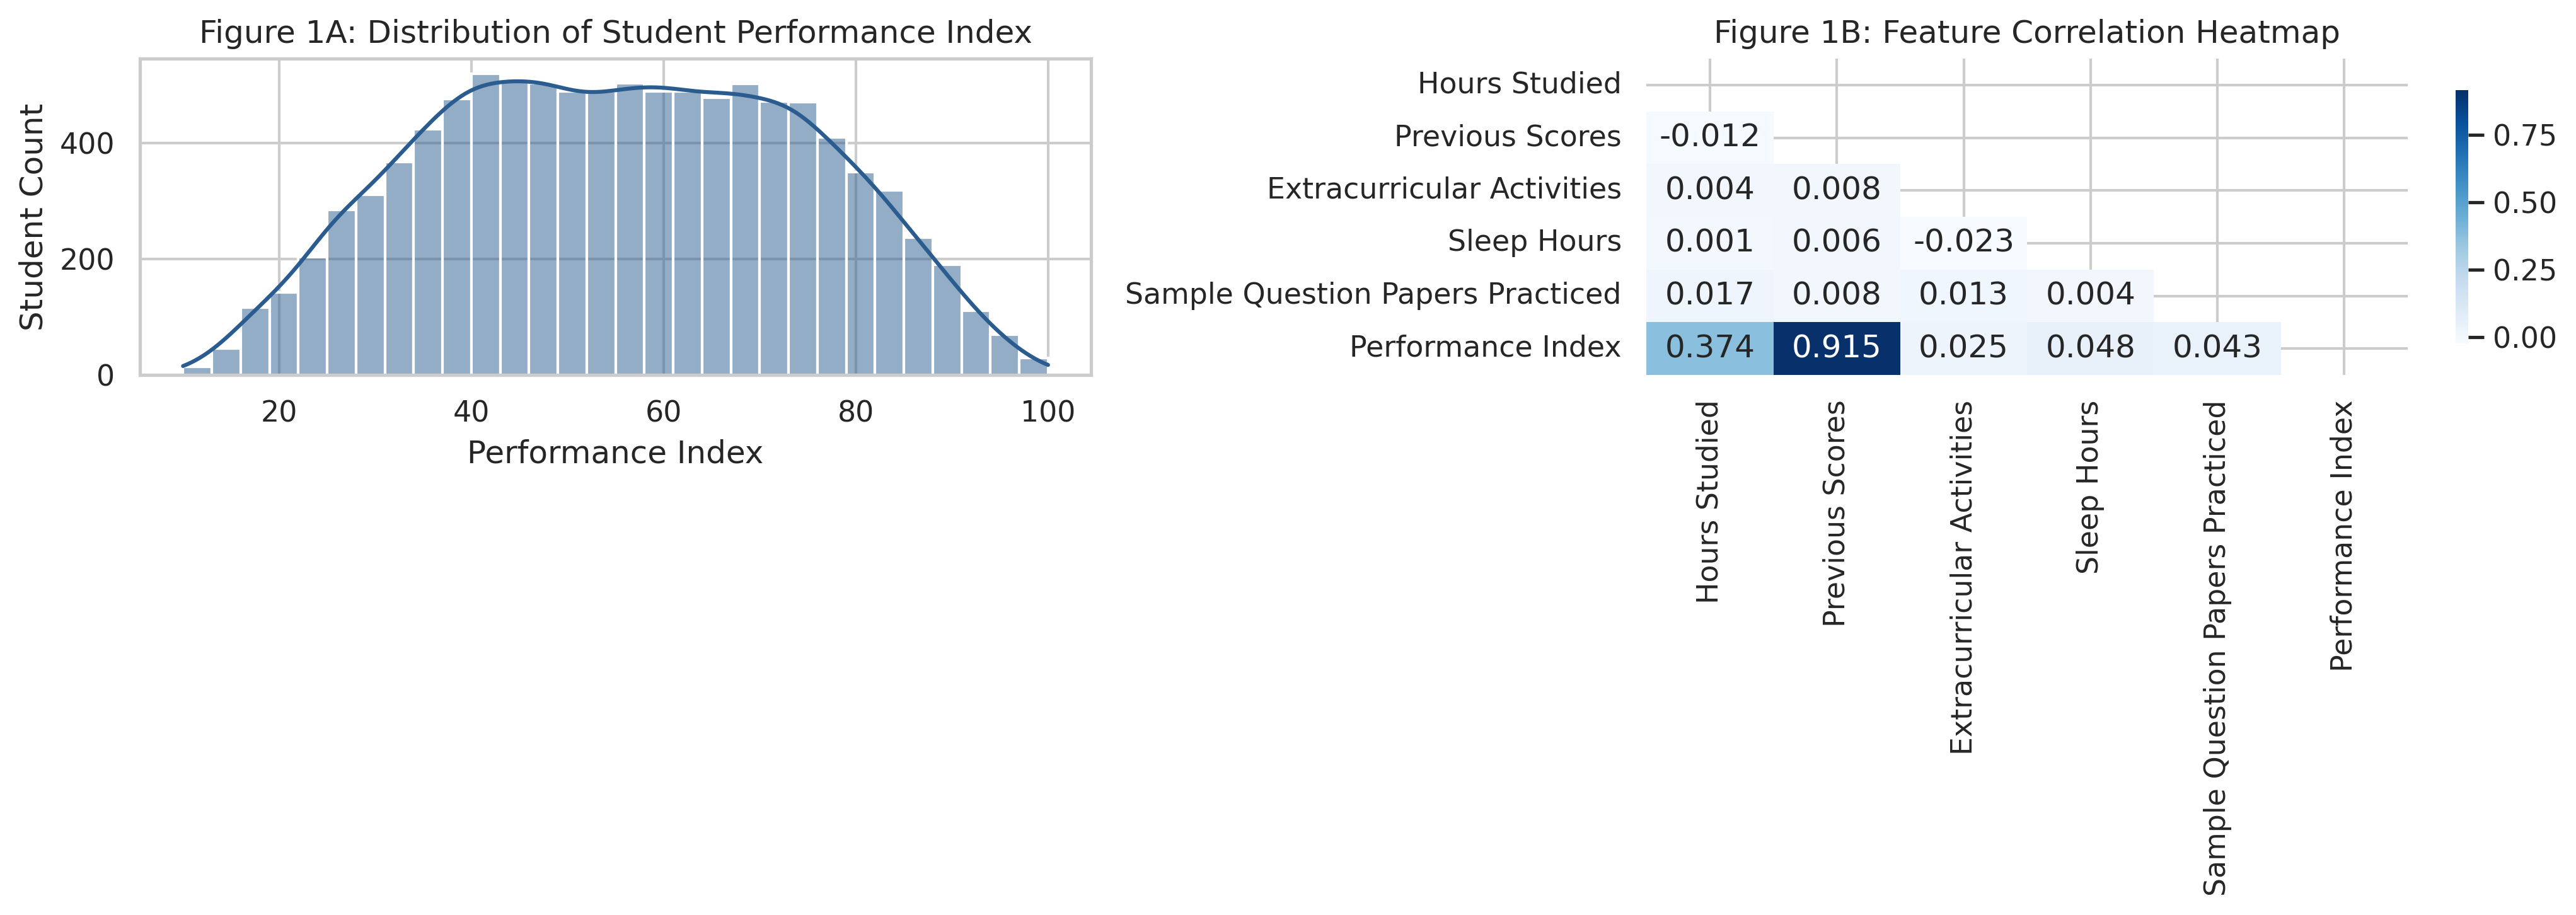

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Target Distribution (Performance Index)
sns.histplot(df['Performance Index'], kde=True, ax=axes[0], color='#2b5c8f', bins=30)
axes[0].set_title('Figure 1A: Distribution of Student Performance Index')
axes[0].set_xlabel('Performance Index')
axes[0].set_ylabel('Student Count')

# Plot 2: Correlation Matrix Heatmap
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='Blues', mask=mask, ax=axes[1], cbar_kws={"shrink": .8})
axes[1].set_title('Figure 1B: Feature Correlation Heatmap')

plt.tight_layout()
plt.savefig('fig1_eda_distribution_correlation.png', bbox_inches='tight')
plt.show()

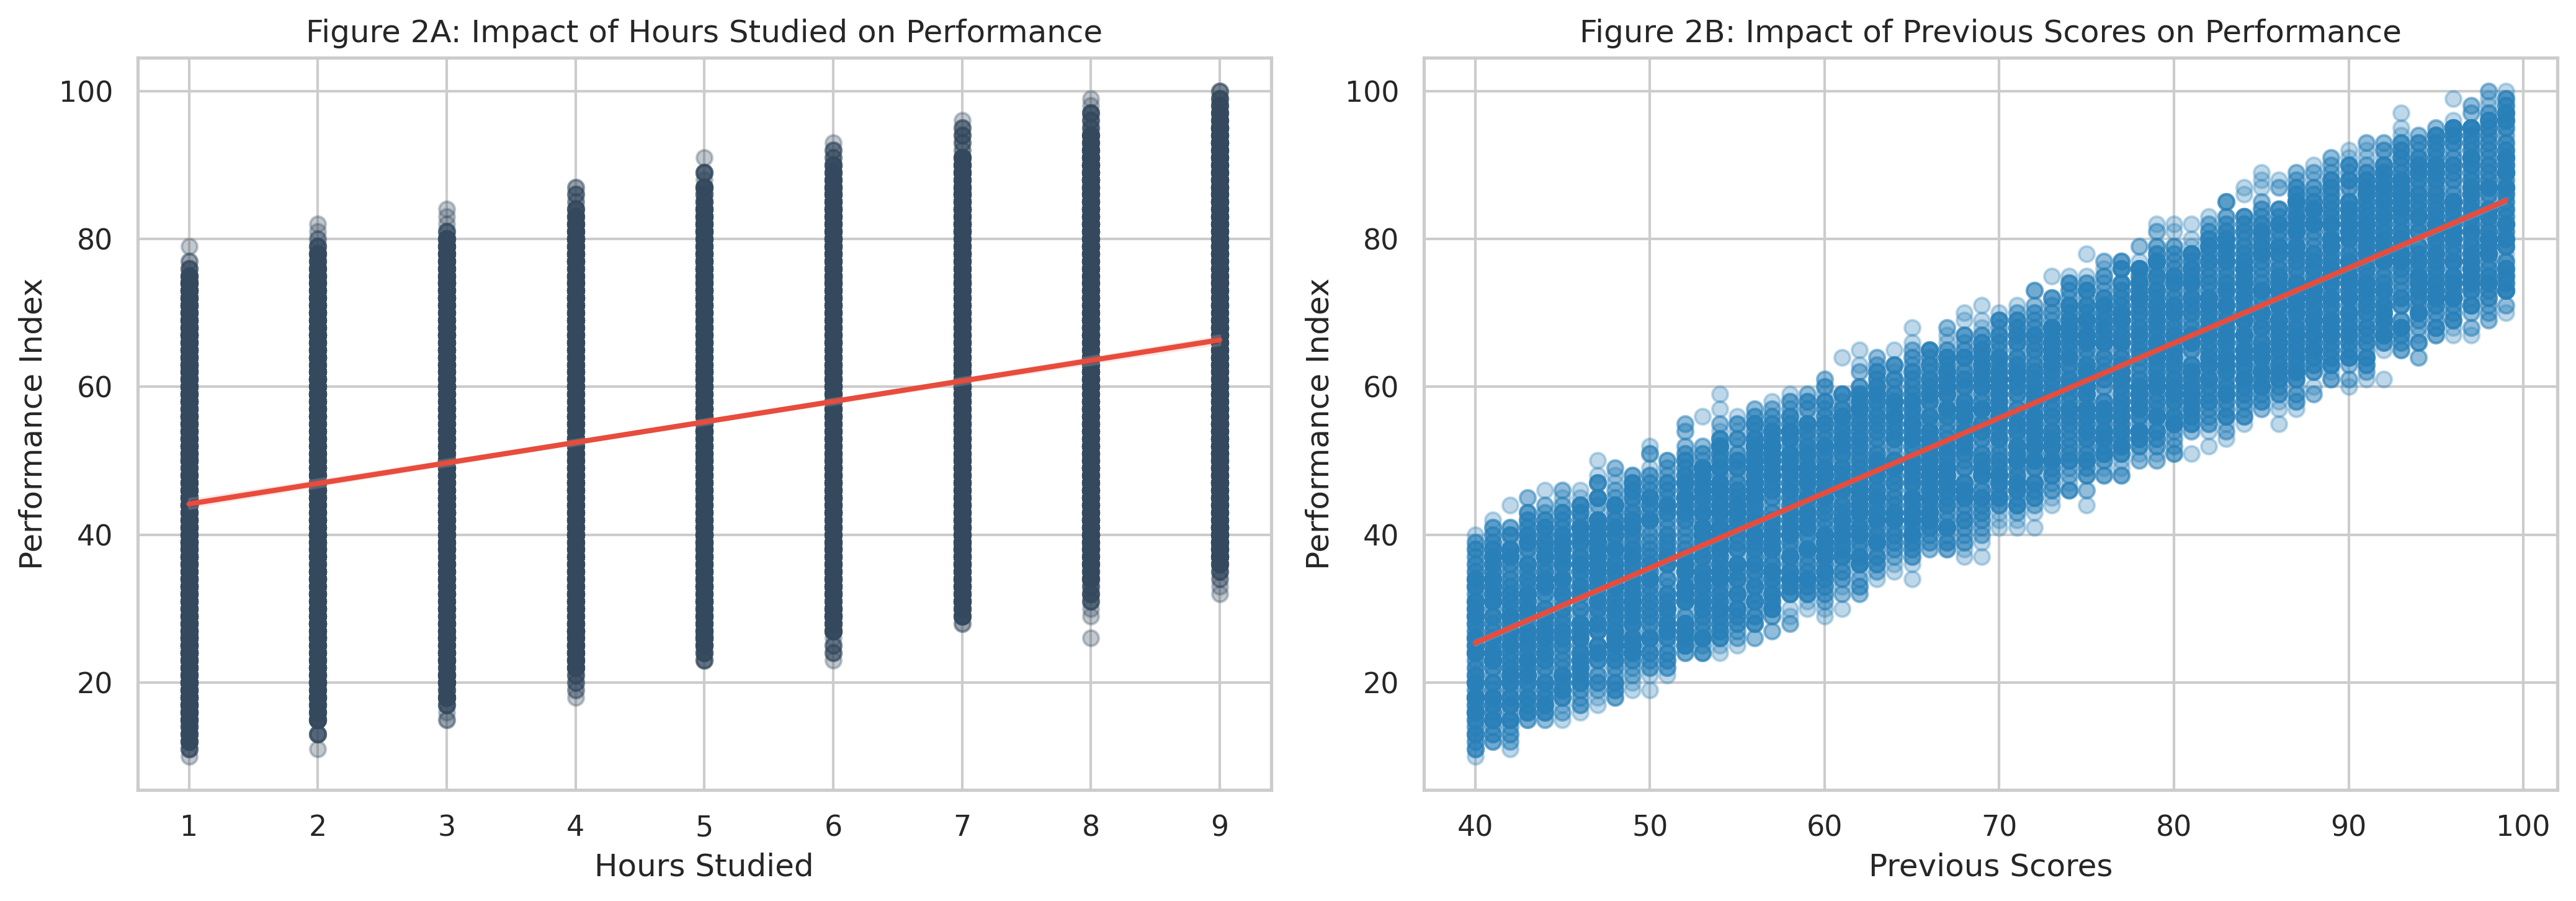

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Hours Studied vs Performance Index
sns.regplot(data=df, x='Hours Studied', y='Performance Index', ax=axes[0], 
            scatter_kws={'alpha':0.3, 'color':'#34495e'}, line_kws={'color':'#e74c3c', 'linewidth':2})
axes[0].set_title('Figure 2A: Impact of Hours Studied on Performance')

# Previous Scores vs Performance Index
sns.regplot(data=df, x='Previous Scores', y='Performance Index', ax=axes[1], 
            scatter_kws={'alpha':0.3, 'color':'#2980b9'}, line_kws={'color':'#e74c3c', 'linewidth':2})
axes[1].set_title('Figure 2B: Impact of Previous Scores on Performance')

plt.tight_layout()
plt.savefig('fig2_feature_trends.png', bbox_inches='tight')
plt.show()

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Feature/Target Separation
X = df.drop(columns=['Performance Index'])
y = df['Performance Index']

# Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Overfitting Check Models
lr_diag = LinearRegression()
lr_diag.fit(X_train_scaled, y_train)

rf_diag = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
rf_diag.fit(X_train, y_train)

# Compare Train vs Test Performance
overfitting_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest (depth=10)'],
    'Train R²': [lr_diag.score(X_train_scaled, y_train), rf_diag.score(X_train, y_train)],
    'Test R²': [lr_diag.score(X_test_scaled, y_test), rf_diag.score(X_test, y_test)],
    'Difference (Train - Test)': [
        lr_diag.score(X_train_scaled, y_train) - lr_diag.score(X_test_scaled, y_test),
        rf_diag.score(X_train, y_train) - rf_diag.score(X_test, y_test)
    ]
})

print("--- OVERFITTING / UNDERFITTING DIAGNOSTIC TABLE ---")
display(overfitting_df)

--- OVERFITTING / UNDERFITTING DIAGNOSTIC TABLE ---


,Model,Train R²,Test R²,Difference (Train - Test)
0,Linear Regression,0.988690,0.988983,-0.000293
1,Random Forest (depth=10),0.992816,0.987266,0.005549


In [13]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.linear_model import Lasso

models = {
    "Linear Regression": (LinearRegression(), True),
    "Ridge Regression": (Ridge(alpha=1.0), True),
    "Lasso Regression": (Lasso(alpha=0.1), True),
    "Gradient Boosting": (GradientBoostingRegressor(n_estimators=100, random_state=42), False),
    "Random Forest": (RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42), False),
    "Extra Trees": (ExtraTreesRegressor(n_estimators=100, random_state=42), False),
    "Decision Tree": (DecisionTreeRegressor(max_depth=8, random_state=42), False)
}

results = []
trained_models = {}

for name, (model, needs_scaling) in models.items():
    X_tr = X_train_scaled if needs_scaling else X_train
    X_te = X_test_scaled if needs_scaling else X_test
    
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    
    results.append({
        "Model Algorithm": name,
        "R² Score": round(r2, 6),
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4)
    })
    trained_models[name] = (model, y_pred)

benchmark_table = pd.DataFrame(results).sort_values(by="R² Score", ascending=False)

print("--- TABLE I: COMPREHENSIVE REGRESSION BENCHMARK ---")
display(benchmark_table)
benchmark_table.to_csv('table1_model_benchmark.csv', index=False)

--- TABLE I: COMPREHENSIVE REGRESSION BENCHMARK ---


,Model Algorithm,R² Score,MAE,RMSE
0,Linear Regression,0.988983,1.6111,2.0206
1,Ridge Regression,0.988982,1.6112,2.0207
2,Lasso Regression,0.988733,1.6267,2.0434
3,Gradient Boosting,0.988222,1.6578,2.0892
4,Random Forest,0.987266,1.7308,2.1723
6,Decision Tree,0.983901,1.9514,2.4426
5,Extra Trees,0.983169,1.9964,2.4974


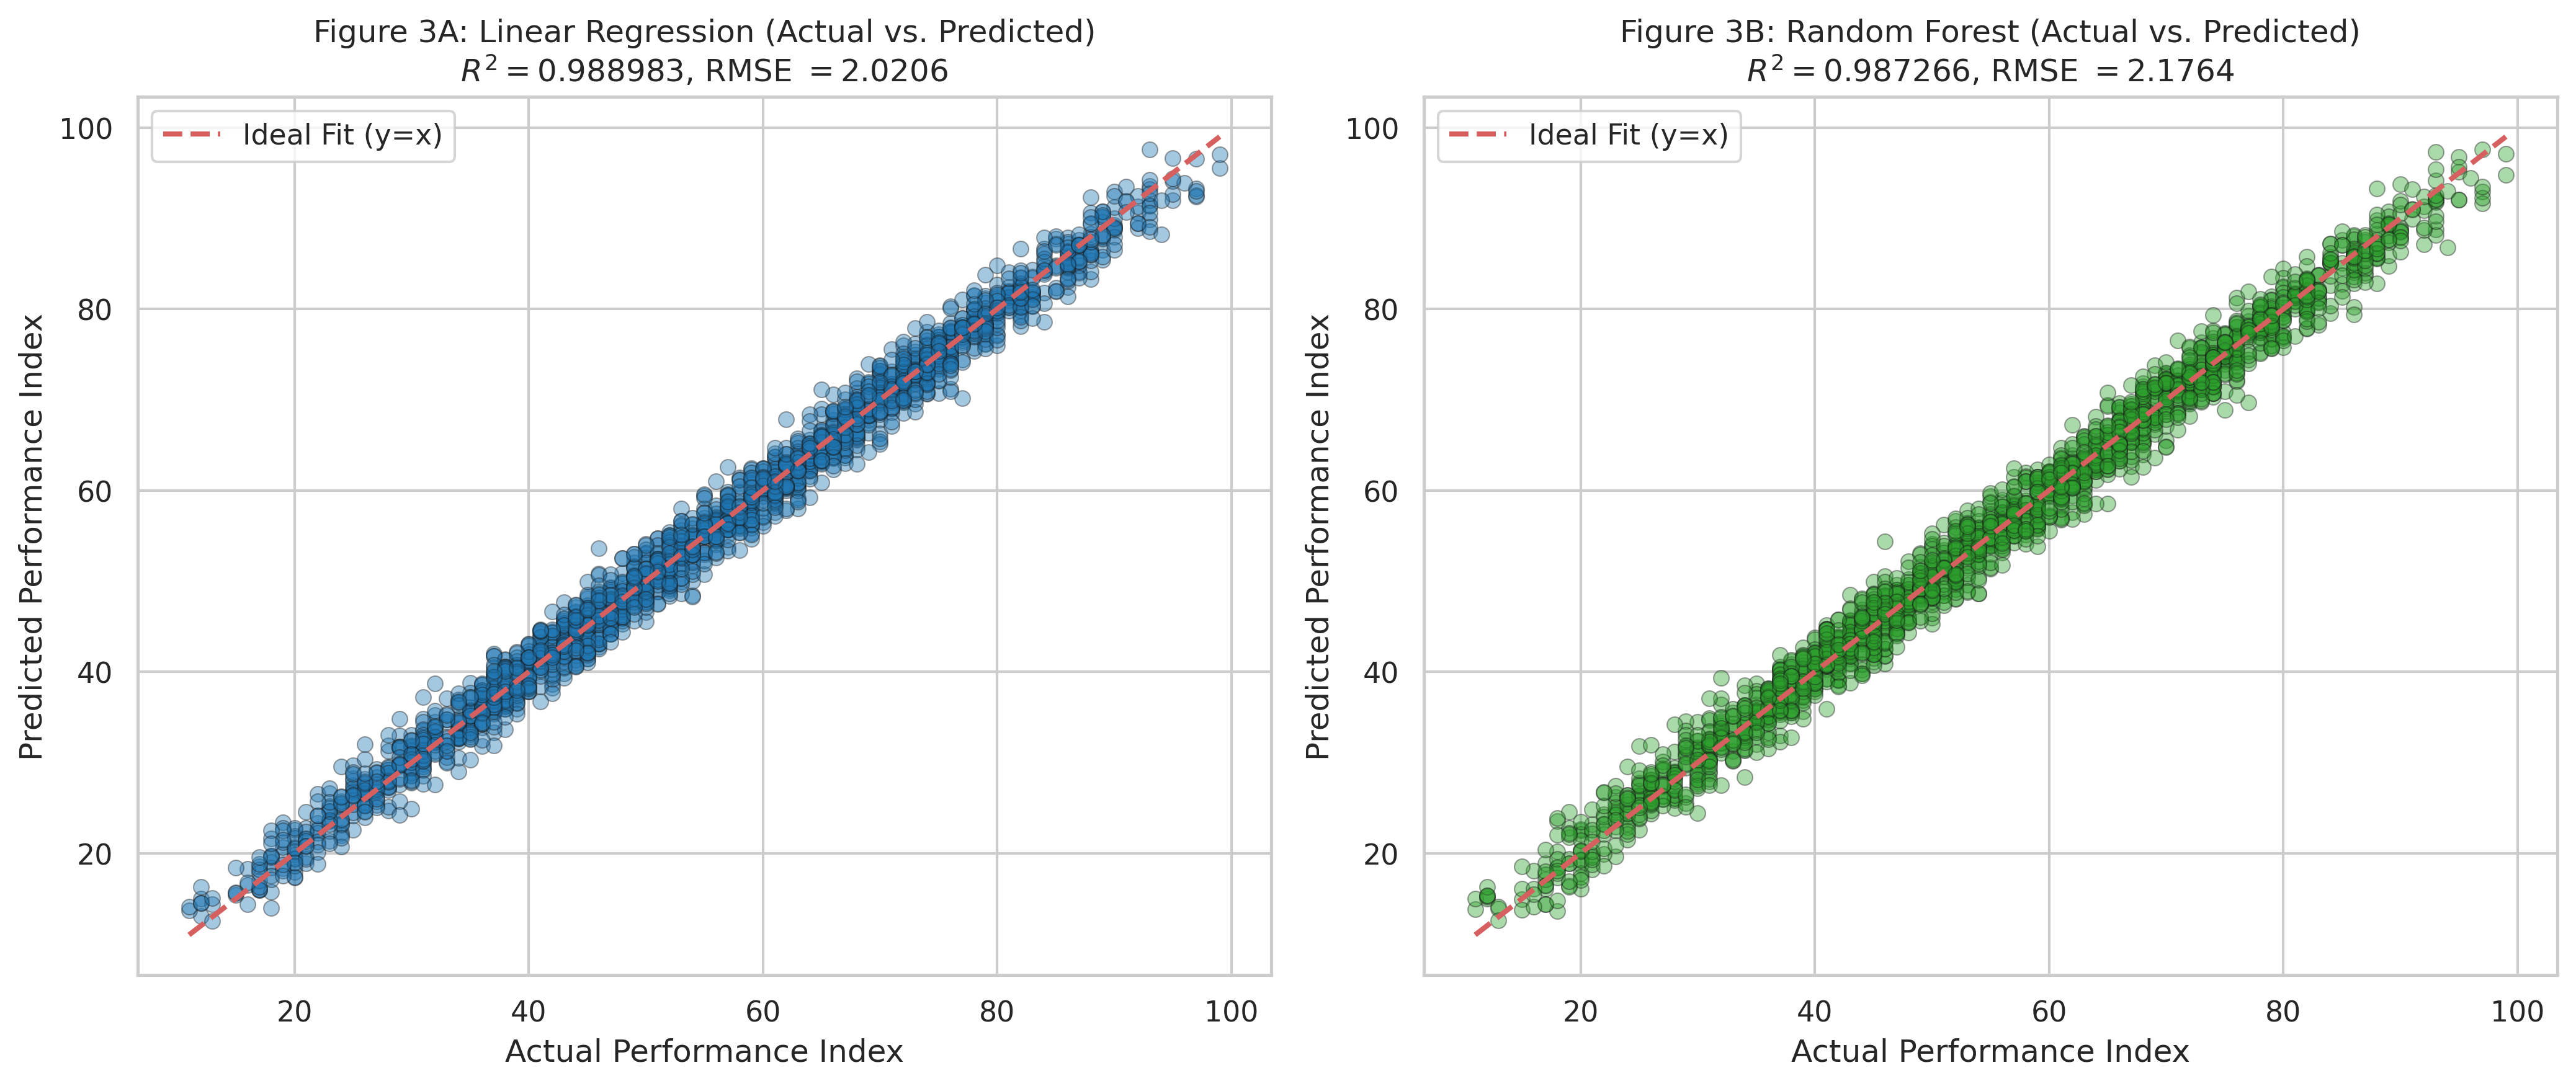

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Linear Regression Plot
y_pred_lr = trained_models["Linear Regression"][1]
axes[0].scatter(y_test, y_pred_lr, alpha=0.4, color='#1f77b4', edgecolors='k', linewidths=0.5)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit (y=x)')
axes[0].set_title('Figure 3A: Linear Regression (Actual vs. Predicted)\n$R^2 = 0.988983$, RMSE $= 2.0206$')
axes[0].set_xlabel('Actual Performance Index')
axes[0].set_ylabel('Predicted Performance Index')
axes[0].legend()

# Random Forest Plot
y_pred_rf = trained_models["Random Forest"][1]
axes[1].scatter(y_test, y_pred_rf, alpha=0.4, color='#2ca02c', edgecolors='k', linewidths=0.5)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit (y=x)')
axes[1].set_title('Figure 3B: Random Forest (Actual vs. Predicted)\n$R^2 = 0.987266$, RMSE $= 2.1764$')
axes[1].set_xlabel('Actual Performance Index')
axes[1].set_ylabel('Predicted Performance Index')
axes[1].legend()

plt.tight_layout()
plt.savefig('fig3_actual_vs_predicted.png', bbox_inches='tight')
plt.show()

<>:14: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_50/1573316430.py:14: SyntaxWarning: invalid escape sequence '\m'
  axes[1].set_title('Figure 4B: Residual Error Distribution ($\mu \\approx 0$)')


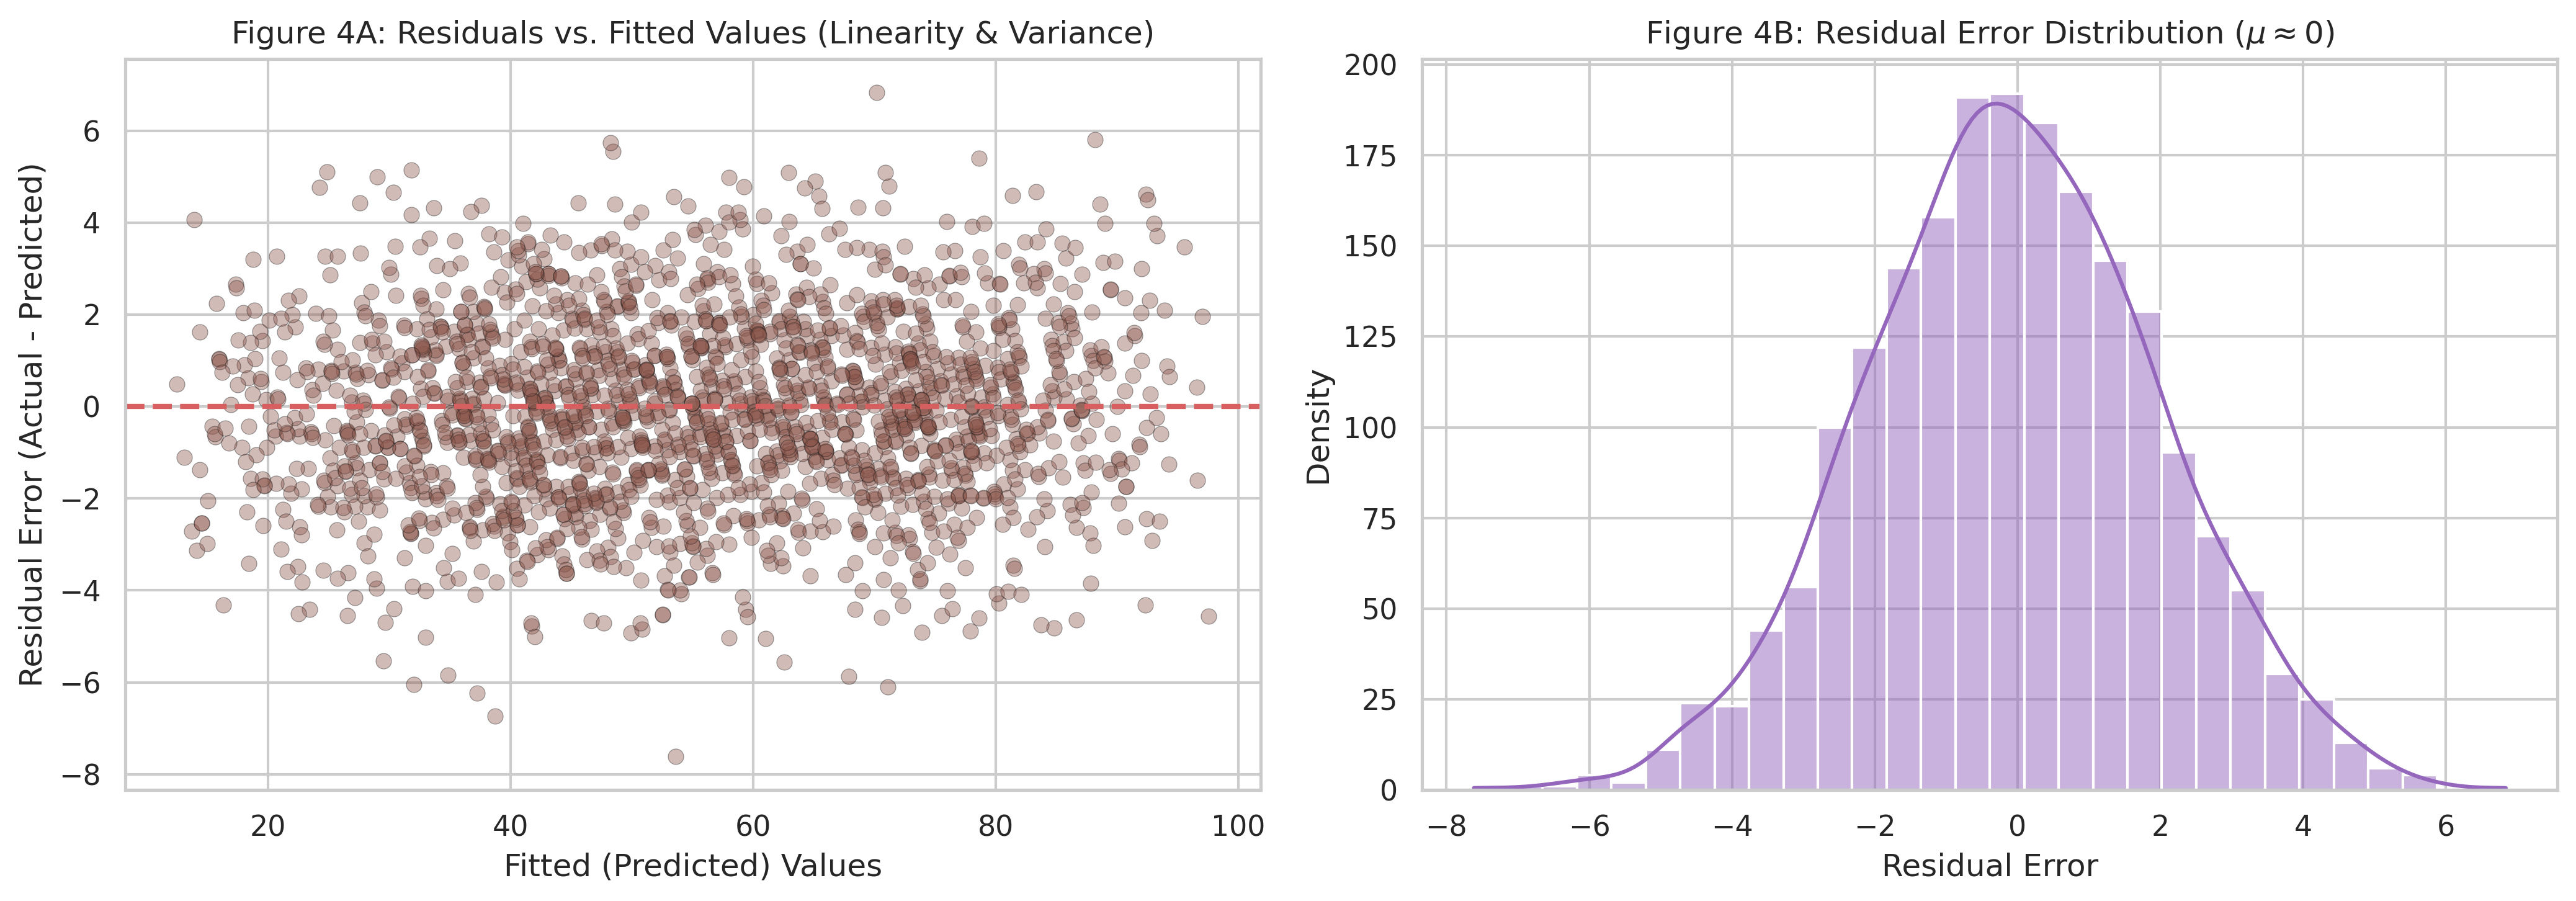

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

residuals_lr = y_test - y_pred_lr

# Plot 1: Residuals vs Fitted Values (Homoscedasticity)
axes[0].scatter(y_pred_lr, residuals_lr, alpha=0.4, color='#8c564b', edgecolors='k', linewidths=0.3)
axes[0].axhline(y=0, color='r', linestyle='--', linewidth=2)
axes[0].set_title('Figure 4A: Residuals vs. Fitted Values (Linearity & Variance)')
axes[0].set_xlabel('Fitted (Predicted) Values')
axes[0].set_ylabel('Residual Error (Actual - Predicted)')

# Plot 2: Residual Error Distribution (Normality)
sns.histplot(residuals_lr, kde=True, ax=axes[1], color='#9467bd', bins=30)
axes[1].set_title('Figure 4B: Residual Error Distribution ($\mu \\approx 0$)')
axes[1].set_xlabel('Residual Error')
axes[1].set_ylabel('Density')

plt.tight_layout()
plt.savefig('fig4_residual_diagnostics.png', bbox_inches='tight')
plt.show()

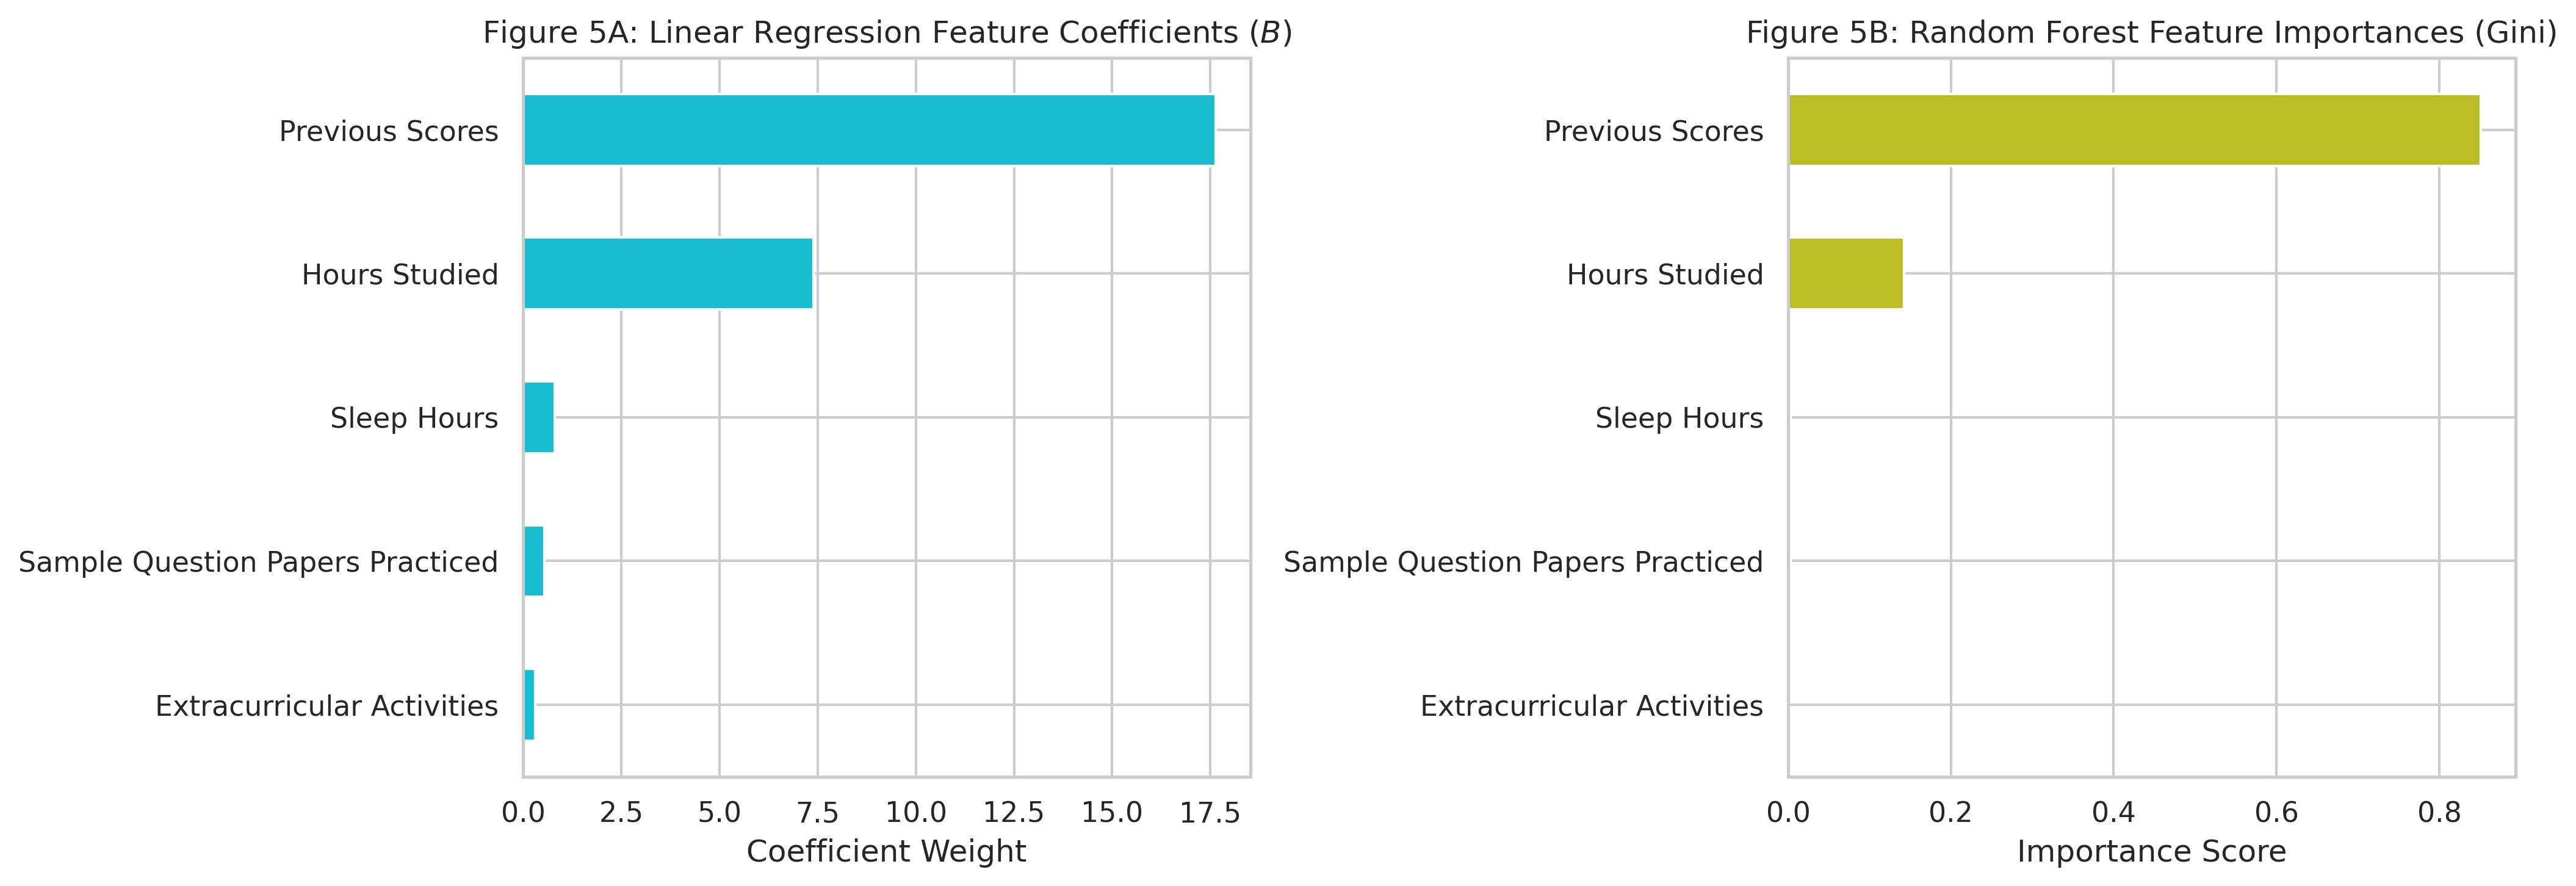

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Linear Regression Coefficients
lr_model = trained_models["Linear Regression"][0]
coef_series = pd.Series(lr_model.coef_, index=X.columns).sort_values()

coef_series.plot(kind='barh', ax=axes[0], color='#17becf')
axes[0].set_title('Figure 5A: Linear Regression Feature Coefficients ($B$)')
axes[0].set_xlabel('Coefficient Weight')

# Random Forest Gini Importances
rf_model = trained_models["Random Forest"][0]
imp_series = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()

imp_series.plot(kind='barh', ax=axes[1], color='#bcbd22')
axes[1].set_title('Figure 5B: Random Forest Feature Importances (Gini)')
axes[1].set_xlabel('Importance Score')

plt.tight_layout()
plt.savefig('fig5_feature_importance.png', bbox_inches='tight')
plt.show()

In [17]:
# Save Best Model, Scaler, and Metadata
joblib.dump(lr_model, 'best_student_performance_lr_model.joblib')
joblib.dump(scaler, 'feature_scaler.joblib')

print("Model & Scaler artifacts saved successfully as '.joblib' files!")

# Verification: Load and test inference
loaded_model = joblib.load('best_student_performance_lr_model.joblib')
loaded_scaler = joblib.load('feature_scaler.joblib')

# Sample Student Test Input: [Hours Studied=7, Prev Scores=85, Extracurricular=1, Sleep=7, Sample Papers=4]
sample_input = np.array([[7, 85, 1, 7, 4]])
sample_scaled = loaded_scaler.transform(sample_input)
sample_pred = loaded_model.predict(sample_scaled)

print(f"\n[Test Inference Check] Predicted Performance Index: {sample_pred[0]:.2f}")

Model & Scaler artifacts saved successfully as '.joblib' files!

[Test Inference Check] Predicted Performance Index: 77.20


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
